# Hybridation SAGE + Sem-Detect par SVM

**Question.** Un SVM très simple, entraîné sur les **logits de sortie** des deux détecteurs figés, fait-il mieux que chacun des deux seuls ?

**Entrées par review** (aucun des deux systèmes n'est modifié) :

| Variable | Définition | Remarque |
|---|---|---|
| `sd_ai` | $\log P_{ai} - \log P_{human}$ (Sem-Detect) | égal à la différence des scores bruts du LightGBM, puisque la sortie est un softmax |
| `sd_rw` | $\log P_{rewrite} - \log P_{human}$ (Sem-Detect) | le softmax à 3 classes a 2 degrés de liberté |
| `z_SAGE-APRDB`, `z_SAGE-SD` | $\log p - \log(1 - p)$ (SAGE) | logit reconstruit depuis la probabilité en cache ; la saturation float32 est mesurée en cellule 6 |

**Protocole.**

1. **Tâche** : humain contre IA (réécritures exclues), comme dans le notebook récapitulatif. Seules les cibles classées par Sem-Detect sont gardées.
2. **Données** : Sem-Detect DB test en configurations E0 et E2, et pilote APRDB en E3 (a). Pas de sorties Sem-Detect sur le train : leur calcul coûterait environ 7 h de GPU.
3. **Évaluation dans un même dataset** : validation croisée **imbriquée et groupée**.
   - Boucle externe : 5 plis `StratifiedGroupKFold`, groupés par papier (Sem-Detect DB) ou par `review-id` (APRDB). On obtient ainsi des scores hors pli pour chaque cible.
   - Boucle interne : 3 plis pour choisir `C` (et `gamma` en RBF).
   - Le `StandardScaler` est dans le pipeline, donc ajusté sur chaque pli d'entraînement uniquement.
4. **Évaluation entre datasets** : SVM entraîné sur tout un dataset, appliqué à l'autre. Les poids de fusion transfèrent-ils ?
5. **Témoins** : chaque détecteur seul, **brut** et **passé par le même SVM**. La comparaison qui répond à la question est **« Hybride » contre « Sem-Detect (SVM) »**. Un SVM sur (`sd_ai`, `sd_rw`) peut déjà battre $P_{ai}$ brut, puisqu'il exploite aussi `sd_rw`. Un gain mesuré contre le brut confondrait donc l'apport de SAGE avec celui du réajustement de Sem-Detect.
6. **Noyaux** : linéaire (la fusion est alors une somme pondérée de logits, et les poids sont lisibles) et RBF (interactions, par exemple « croire SAGE quand Sem-Detect hésite »).

**Prérequis.** Les caches de Sem-Detect (E0, E2, E3) et les scores SAGE du notebook récapitulatif (`CACHE_DIR/recap/sage_scores_*.parquet`). S'ils manquent, la cellule 6 les recalcule, ce qui demande que **le GPU 1 soit libre**.

In [1]:
# notebook : hybrid_svm.ipynb — cellule 1 : imports et configuration
import hashlib
import logging
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import auc, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from src.config import PROJ_ROOT, RESULT_DIR
from src.data.dataset_semdetect import SemDetectDataset
from src.detector.sem_detect.claims_llm import LocalClaimExtractor
from src.detector.sem_detect.feature_store import SemDetectFeatureStore
from src.detector.sem_detect.references import (
    build_feature_matrix, fixed_models_references, paper_protocol_references, predict_proba,
)
from src.detector.sem_detect.semdetect.classifier import FEATURE_DISPLAY_NAMES, SemDetectClassifier
from src.detector.sem_detect.text_cleaning import CLEANERS

logging.basicConfig(level=logging.INFO)
logging.getLogger("httpx").setLevel(logging.WARNING)

CACHE_ROOT = Path(os.environ["CACHE_DIR"])
STORE_ROOT = CACHE_ROOT / "sem_detect_store"
E2_DIR = CACHE_ROOT / "sem_detect_e2"
E3_DIR = CACHE_ROOT / "sem_detect_e3"
RECAP_DIR = CACHE_ROOT / "recap"              # cache des scores SAGE partagé avec le notebook récapitulatif
HYB_DIR = CACHE_ROOT / "hybrid_svm"
RECAP_DIR.mkdir(parents=True, exist_ok=True)
HYB_DIR.mkdir(parents=True, exist_ok=True)

REVISION = "18b74b551670bff6b04e57570232a1694997863b"
HF_SOURCE = f"hf:Sem-Detect/ML_Conferences-Peer-Reviews@{REVISION}"
TEXT_SOURCE = f"{HF_SOURCE}:clean_review"
CLAIMS_TAG_EXPECTED = "vllm:qwen3-32b:0902bb5d60"

FEATURES_DEVICE = "cuda:0"   # aucun modèle chargé si les caches sont complets
SAGE_DEVICE = "cuda:0"       # GRU de SAGE ; sa segmentation utilise cuda:1 (codé en dur)
SAGE_PRESETS = {"SAGE-APRDB": "train_sage_gru_v3", "SAGE-SD": "train_sage_gru_v3_semdetect"}
N_BOOT = 1000
N_OUTER, N_INNER, CV_SEED = 5, 3, 0
METRIC_NAMES = ["AUC", "TPR@1%", "TPR@5%"]
TABLES = {}

/home/cyaiche/generated_text_detection_hub/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-08 09:51:14.601 | INFO     | src.config:<module>:12 - PROJ_ROOT path is: /home/cyaiche/generated_text_detection_hub


In [2]:
# notebook : hybrid_svm.ipynb — cellule 2 : métriques et bootstrap en grappes (identiques au récapitulatif)
def all_metrics(y: np.ndarray, s: np.ndarray) -> dict:
    fpr, tpr, _ = roc_curve(y, s)
    return {"AUC": float(auc(fpr, tpr)),
            "TPR@1%": float(np.interp(0.01, fpr, tpr)),
            "TPR@5%": float(np.interp(0.05, fpr, tpr))}


def make_evalset(ids, y, clusters, n_boot: int = N_BOOT, seed: int = 0) -> dict:
    ids = pd.Index(list(ids))
    if not ids.is_unique:
        raise ValueError("identifiants dupliqués dans l'ensemble d'évaluation")
    y = np.asarray(y, dtype=int)
    codes, _ = pd.factorize(pd.Series(list(clusters)).astype(str))
    order = np.argsort(codes, kind="stable")
    members = np.split(order, np.cumsum(np.bincount(codes))[:-1])
    rng = np.random.default_rng(seed)
    boot = []
    while len(boot) < n_boot:
        idx = np.concatenate([members[k] for k in rng.integers(0, len(members), len(members))])
        if 0 < y[idx].sum() < len(idx):
            boot.append(idx)
    return {"ids": ids, "y": y, "boot": boot, "n_clusters": len(members)}


def aligned(es: dict, s: pd.Series) -> np.ndarray:
    v = s.reindex(es["ids"]).to_numpy(dtype=float)
    if np.isnan(v).any():
        raise ValueError(f"{int(np.isnan(v).sum())} score(s) manquant(s) pour {s.name!r}")
    return v


def score_table(es: dict, scores: dict) -> pd.DataFrame:
    y, rows = es["y"], {}
    for name, s in scores.items():
        v = aligned(es, s)
        point = all_metrics(y, v)
        boots = pd.DataFrame([all_metrics(y[i], v[i]) for i in es["boot"]])
        row = {"n": len(y), "n IA": int(y.sum()), "n nég.": int(len(y) - y.sum()), "grappes": es["n_clusters"]}
        for m in METRIC_NAMES:
            row[m] = point[m]
            row[f"{m}_lo"], row[f"{m}_hi"] = np.percentile(boots[m], [2.5, 97.5])
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def paired_delta(es: dict, s_a: pd.Series, s_b: pd.Series) -> pd.DataFrame:
    """métrique(b) − métrique(a), mêmes cibles et mêmes rééchantillonnages."""
    y, a, b = es["y"], aligned(es, s_a), aligned(es, s_b)
    pa, pb = all_metrics(y, a), all_metrics(y, b)
    d = pd.DataFrame([{m: mb[m] - ma[m] for m in METRIC_NAMES}
                      for ma, mb in ((all_metrics(y[i], a[i]), all_metrics(y[i], b[i])) for i in es["boot"])])
    return pd.DataFrame({m: {"Δ (b − a)": pb[m] - pa[m],
                             "IC95 bas": np.percentile(d[m], 2.5), "IC95 haut": np.percentile(d[m], 97.5),
                             "part bootstrap Δ ≤ 0": float((d[m] <= 0).mean())}
                         for m in METRIC_NAMES}).T


def delta_table(es: dict, pairs: dict) -> pd.DataFrame:
    return pd.concat({label: paired_delta(es, a, b) for label, (a, b) in pairs.items()},
                     names=["comparaison", "métrique"])


def show(tab: pd.DataFrame, title: str = "") -> None:
    out = pd.DataFrame(index=tab.index)
    for c in ("n", "n IA", "n nég.", "grappes"):
        out[c] = tab[c].astype(int)
    for m in METRIC_NAMES:
        out[m] = [f"{p:.4f} [{lo:.3f}, {hi:.3f}]" for p, lo, hi in zip(tab[m], tab[f"{m}_lo"], tab[f"{m}_hi"])]
    for c in ("AUC moy. plis", "AUC é.-t. plis"):
        if c in tab:
            out[c] = tab[c].round(4)
    if title:
        print(title)
    display(out)

In [3]:
# notebook : hybrid_svm.ipynb — cellule 3 : SAGE (même hash que run_eval) et cache de scores partagé
from hydra import compose, initialize_config_dir
from hydra.core.global_hydra import GlobalHydra
from omegaconf import OmegaConf

from src.detector.subjectivity_aware_generation_estimator.sage import SageGRU
from src.evaluation.eval_utils import generate_config_hash


def compose_train(preset: str):
    GlobalHydra.instance().clear()
    with initialize_config_dir(config_dir=str(PROJ_ROOT / "conf"), version_base="1.3"):
        return compose(config_name="train", overrides=[f"experiment/train={preset}"])


SAGE_META = {}
for name, preset in SAGE_PRESETS.items():
    cfg = compose_train(preset)
    h = generate_config_hash(cfg, exclude=["hardware"])
    art = Path(RESULT_DIR) / h / "artifact.joblib"
    SAGE_META[name] = {"preset": preset, "hash": h,
                       "meta": OmegaConf.create(OmegaConf.to_container(cfg, resolve=True))}
    print(f"{name:<11} preset={preset:<28} hash={h}  artefact {'OK' if art.exists() else 'ABSENT'}")
    if not art.exists():
        raise FileNotFoundError(art)
assert SAGE_META["SAGE-APRDB"]["hash"].startswith("40267e07"), "hash SAGE-APRDB différent de l'artefact de référence"

_SAGE_MODELS = {}


def _sage_model(name: str) -> SageGRU:
    if name not in _SAGE_MODELS:
        m = SAGE_META[name]
        _SAGE_MODELS[name] = SageGRU(m["hash"], m["meta"], device=SAGE_DEVICE, save_segmented=False)
    return _SAGE_MODELS[name]


def _md5(text: str) -> str:
    return hashlib.md5(text.encode("utf-8")).hexdigest()


def sage_scores(name: str, ids, texts, chunk: int = 500) -> pd.Series:
    """P(IA) de SAGE, cache (identifiant, MD5 du texte) commun avec semdetect_sage_recap.ipynb."""
    ids, texts = list(ids), list(texts)
    if len(set(ids)) != len(ids):
        raise ValueError("identifiants dupliqués")
    path = RECAP_DIR / f"sage_scores_{name}_{SAGE_META[name]['hash'][:8]}.parquet"
    cache = pd.read_parquet(path) if path.exists() else pd.DataFrame(columns=["id", "md5", "score"])
    known = {i: (m, s) for i, m, s in zip(cache["id"], cache["md5"], cache["score"])}
    md5s = [_md5(t) for t in texts]
    todo = [k for k, (i, m) in enumerate(zip(ids, md5s)) if known.get(i, (None, None))[0] != m]
    print(f"{name} : {len(ids) - len(todo)} en cache, {len(todo)} à scorer")
    if todo:
        free, _ = torch.cuda.mem_get_info(1)
        if free < 8 * 2**30:
            raise RuntimeError(f"GPU 1 : {free / 2**30:.1f} Go libres, arrêter vLLM avant de scorer SAGE")
    for start in range(0, len(todo), chunk):
        part = todo[start:start + chunk]
        p = np.asarray(_sage_model(name).evaluate([texts[k] for k in part]), dtype=float).ravel()
        if p.shape != (len(part),):
            raise ValueError(f"SAGE a rendu {p.shape} scores pour {len(part)} textes")
        for k, v in zip(part, p):
            known[ids[k]] = (md5s[k], float(v))
        out = pd.DataFrame([(i, m, s) for i, (m, s) in known.items()], columns=["id", "md5", "score"])
        tmp = path.with_suffix(".tmp")
        out.to_parquet(tmp, index=False)
        tmp.replace(path)
        print(f"  {min(start + chunk, len(todo))}/{len(todo)}")
    return pd.Series([known[i][1] for i in ids], index=ids, name=name)


EPS_SAGE = 1e-7   # résolution de float32 près de 1 : en deçà, la probabilité est saturée


def sage_logit(p: pd.Series) -> pd.Series:
    q = p.clip(EPS_SAGE, 1 - EPS_SAGE)
    return np.log(q) - np.log1p(-q)


def sd_logits(P: pd.DataFrame, eps: float = 1e-12) -> pd.DataFrame:
    """Log-ratios contre la classe human = différences des scores bruts du LightGBM (softmax)."""
    q = P.clip(lower=eps)
    return pd.DataFrame({"sd_ai": np.log(q["p_ai"]) - np.log(q["p_human"]),
                         "sd_rw": np.log(q["p_rewrite"]) - np.log(q["p_human"])}, index=P.index)

/data2/cyaiche/cache_dir
SAGE-APRDB  preset=train_sage_gru_v3            hash=40267e07f7acff6aea5cee99ae7abf31  artefact OK
SAGE-SD     preset=train_sage_gru_v3_semdetect  hash=69ec0e68db42613e302cccb422aab2db  artefact OK


In [4]:
# notebook : hybrid_svm.ipynb — cellule 4 : Sem-Detect DB, Sem-Detect E0 et E2 depuis les caches
te = SemDetectDataset(config={
    "name": "sem_detect", "repo_id": "Sem-Detect/ML_Conferences-Peer-Reviews", "revision": REVISION,
    "split": "test", "conference": None, "date": None, "generator": None,
    "label_mode": "three_class", "balance": "none", "subset_size": None,
    "val_fraction": None, "val_seed": 0,
    "no_duplicate": True, "keep_meta": True, "with_paper": False, "keep_claims": True,
    "exclude_ids_path": None, "seed": 0,
}).to_pandas()
te_idx = te.set_index("review-id")

clf = SemDetectClassifier(str(PROJ_ROOT / "src/detector/sem_detect/models/lightgbm_best_model.pkl"))
CLAIMS_TAG = LocalClaimExtractor(cache_root=CACHE_ROOT, served_model="qwen3-32b").source_tag
assert CLAIMS_TAG == CLAIMS_TAG_EXPECTED, f"source de claims {CLAIMS_TAG} != {CLAIMS_TAG_EXPECTED}"

store_e0 = SemDetectFeatureStore(root=STORE_ROOT, claims_source=HF_SOURCE, text_source=TEXT_SOURCE,
                                 device=FEATURES_DEVICE)
store_loc = SemDetectFeatureStore(root=STORE_ROOT, claims_source=CLAIMS_TAG, text_source=TEXT_SOURCE,
                                  device=FEATURES_DEVICE)
refs_df = pd.read_parquet(E2_DIR / "local_refs.parquet")
assert (refs_df["claims_status"] == "ok").all(), "références locales sans claims"
REF_MODELS = list(dict.fromkeys(refs_df["generator"]))


def valid_in(store: SemDetectFeatureStore):
    return lambda rid: store.semantic(rid, 1) is not None


def run_semdetect(store: SemDetectFeatureStore, refs_map: dict, target_ids) -> pd.DataFrame:
    X, kept, skipped = build_feature_matrix(store, list(target_ids), refs_map, clf.similarity_threshold)
    return pd.DataFrame(predict_proba(clf, X), index=kept, columns=["p_ai", "p_rewrite", "p_human"])


P_SD = {
    "E0": run_semdetect(store_e0, paper_protocol_references(te, k=3, seed=0, is_valid=valid_in(store_e0)),
                        te["review-id"]),
    "E2": run_semdetect(store_loc, fixed_models_references(te, refs_df, models=REF_MODELS,
                                                           is_valid=valid_in(store_loc)), te["review-id"]),
}
CLASS_TO_IDX = {"ai": 0, "rewrite": 1, "human": 2}
EXPECTED_SD = {"E0": (4373, 0.8418), "E2": (3165, 0.7345)}
for e, P in P_SD.items():
    y = te_idx.loc[P.index, "class"].map(CLASS_TO_IDX).to_numpy()
    f1 = f1_score(y, P.to_numpy().argmax(axis=1), average="macro")
    n0, f0 = EXPECTED_SD[e]
    ok = len(P) == n0 and abs(f1 - f0) < 5e-4
    print(f"{'✅' if ok else '⚠️'} {e} : {len(P)} classées (attendu {n0}) | macro-F1 {f1:.4f} (attendu {f0})")

INFO:src.data.dataset_semdetect:📦 Loading Sem-Detect dataset from cache: /data2/cyaiche/cache_dir/dataset_cache/dataset_deb985b4e19d6e357800ffa800e5bf14.pt
INFO:src.detector.sem_detect.semdetect.classifier:Loading Sem-Detect model from /home/cyaiche/generated_text_detection_hub/src/detector/sem_detect/models/lightgbm_best_model.pkl
/home/cyaiche/generated_text_detection_hub/.venv/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/cyaiche/generated_text_detection_hub/.venv/lib/python3.10/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.8.0 when using version 1.7.2. This might lead to br

✅ E0 : 4373 classées (attendu 4373) | macro-F1 0.8418 (attendu 0.8418)
✅ E2 : 3165 classées (attendu 3165) | macro-F1 0.7345 (attendu 0.7345)


In [5]:
# notebook : hybrid_svm.ipynb — cellule 5 : pilote APRDB, Sem-Detect E3 (a) depuis les caches
universe = pd.read_parquet(E3_DIR / "pilot_universe.parquet")
df_a = universe.copy()
df_a["review-id"] = "aprdb:a:" + df_a["uid"]
df_a["content"] = df_a["content"].map(CLEANERS["a"])
store_a = SemDetectFeatureStore(root=STORE_ROOT, claims_source=CLAIMS_TAG, text_source="aprdb:test:clean_a",
                                device=FEATURES_DEVICE)
refs_a = paper_protocol_references(df_a, k=3, seed=0, key_cols=["group"],
                                   is_valid=lambda rid: store_a.semantic(rid, 1) is not None)
P_B = run_semdetect(store_a, refs_a, df_a.loc[df_a["is_target"], "review-id"])
P_B.index = [r[len("aprdb:a:"):] for r in P_B.index]   # retour à l'uid

meta_B = universe[universe["is_target"]].drop_duplicates("uid").set_index("uid")[
    ["group", "class", "generator", "conference", "year", "content"]]
yb = meta_B.loc[P_B.index, "class"].eq("ai").to_numpy()
auc_b = roc_auc_score(yb, P_B["p_ai"].to_numpy())
ok = len(P_B) == 1850 and abs(auc_b - 0.9799) < 5e-4
print(f"{'✅' if ok else '⚠️'} E3 (a) : {len(P_B)} classées (attendu 1850) | AUC {auc_b:.4f} (attendu 0.9799)")

INFO:src.detector.sem_detect.feature_store:Feature store : 15422 embeddings (fbbbe1608d0e), 1918 stats textuelles (cdedf1ab8567)


✅ E3 (a) : 1850 classées (attendu 1850) | AUC 0.9799 (attendu 0.9799)


In [6]:
# notebook : hybrid_svm.ipynb — cellule 6 : scores SAGE, logits et saturation
Z_SD, Z_B, sat = {}, {}, {}
for name in SAGE_PRESETS:
    p_sd = sage_scores(name, "sd:" + te["review-id"], te["content"]).set_axis(te["review-id"].to_numpy())
    p_b = sage_scores(name, "aprdb:" + meta_B.index.to_series(), meta_B["content"]).set_axis(meta_B.index.to_numpy())
    Z_SD[f"z_{name}"], Z_B[f"z_{name}"] = sage_logit(p_sd), sage_logit(p_b)
    for ds, p in (("Sem-Detect DB", p_sd), ("APRDB pilote", p_b)):
        sat[(name, ds)] = {"saturés à 1": float((p >= 1 - EPS_SAGE).mean()),
                           "saturés à 0": float((p <= EPS_SAGE).mean()),
                           "logit min": float(sage_logit(p).min()), "logit max": float(sage_logit(p).max())}
TABLES["saturation_SAGE"] = pd.DataFrame.from_dict(sat, orient="index")
print("Saturation des probabilités SAGE (float32) : au-delà de ~1 %, exposer le logit brut dans sage.py")
display(TABLES["saturation_SAGE"].round(4))

SAGE-APRDB : 4410 en cache, 0 à scorer
SAGE-APRDB : 1918 en cache, 0 à scorer
SAGE-SD : 4410 en cache, 0 à scorer
SAGE-SD : 1918 en cache, 0 à scorer
Saturation des probabilités SAGE (float32) : au-delà de ~1 %, exposer le logit brut dans sage.py


saturés à 1  saturés à 0  logit min  logit max
SAGE-APRDB Sem-Detect DB          0.0          0.0   -10.1138     8.3918
           APRDB pilote           0.0          0.0   -10.5037     8.8422
SAGE-SD    Sem-Detect DB          0.0          0.0   -10.9619    10.1046
           APRDB pilote           0.0          0.0   -11.0477     8.4936

In [7]:
# notebook : hybrid_svm.ipynb — cellule 7 : tables d'entrée du SVM (humain vs IA, cibles classées par Sem-Detect)
def build_table(P: pd.DataFrame, meta: pd.DataFrame, Z: dict, group_col: str) -> pd.DataFrame:
    ids = P.index[meta.loc[P.index, "class"].isin(["human", "ai"]).to_numpy()]
    T = sd_logits(P.loc[ids])
    T["sd_p_ai"] = P.loc[ids, "p_ai"]
    for col, z in Z.items():
        T[col] = z.loc[ids].to_numpy()
    T["y"] = meta.loc[ids, "class"].eq("ai").astype(int).to_numpy()
    T["group"] = meta.loc[ids, group_col].astype(str).to_numpy()
    T["generator"] = meta.loc[ids, "generator"].to_numpy()
    return T


DATA = {
    "SD-E0": build_table(P_SD["E0"], te_idx, Z_SD, "submission_id"),
    "SD-E2": build_table(P_SD["E2"], te_idx, Z_SD, "submission_id"),
    "APRDB-E3a": build_table(P_B, meta_B, Z_B, "group"),
}
INPUTS = ["sd_ai", "sd_rw", "z_SAGE-APRDB", "z_SAGE-SD"]
for k, T in DATA.items():
    print(f"{k:<10} n={len(T)} (IA {T['y'].sum()}, humaines {(1 - T['y']).sum()}) | grappes {T['group'].nunique()}")
    assert T[INPUTS].notna().all().all() and np.isfinite(T[INPUTS].to_numpy()).all()

print("\nCorrélation de Spearman entre entrées, À CLASSE FIXÉE (faible = complémentarité possible) :")
TABLES["correlations_par_classe"] = pd.concat({
    (k, "IA" if c else "humain"): T[T["y"] == c][INPUTS].corr(method="spearman")
    for k, T in DATA.items() for c in (1, 0)}).round(3)
display(TABLES["correlations_par_classe"])

SD-E0      n=1963 (IA 1364, humaines 599) | grappes 159
SD-E2      n=1436 (IA 1003, humaines 433) | grappes 138
APRDB-E3a  n=1850 (IA 905, humaines 945) | grappes 993

Corrélation de Spearman entre entrées, À CLASSE FIXÉE (faible = complémentarité possible) :


sd_ai  sd_rw  z_SAGE-APRDB  z_SAGE-SD
SD-E0     IA     sd_ai         1.000  0.007        -0.154     -0.029
                 sd_rw         0.007  1.000        -0.145     -0.039
                 z_SAGE-APRDB -0.154 -0.145         1.000     -0.003
                 z_SAGE-SD    -0.029 -0.039        -0.003      1.000
          humain sd_ai         1.000  0.880         0.009      0.071
                 sd_rw         0.880  1.000         0.028      0.053
                 z_SAGE-APRDB  0.009  0.028         1.000      0.340
                 z_SAGE-SD     0.071  0.053         0.340      1.000
SD-E2     IA     sd_ai         1.000 -0.198        -0.069     -0.026
                 sd_rw        -0.198  1.000        -0.264     -0.061
                 z_SAGE-APRDB -0.069 -0.264         1.000     -0.037
                 z_SAGE-SD    -0.026 -0.061        -0.037      1.000
          humain sd_ai         1.000  0.893         0.005      0.077
                 sd_rw         0.893  1.000         0.012      0.056
                 z_SAGE-APRDB  0.005  0.012         1.000      0.327
                 z_SAGE-SD     0.077  0.056         0.327      1.000
APRDB-E3a IA     sd_ai         1.000  0.105         0.256      0.080
                 sd_rw         0.105  1.000         0.033     -0.008
                 z_SAGE-APRDB  0.256  0.033         1.000      0.343
                 z_SAGE-SD     0.080 -0.008         0.343      1.000
          humain sd_ai         1.000  0.904        -0.089      0.011
                 sd_rw         0.904  1.000        -0.077     -0.001
                 z_SAGE-APRDB -0.089 -0.077         1.000      0.464
                 z_SAGE-SD     0.011 -0.001         0.464      1.000

In [8]:
# notebook : hybrid_svm.ipynb — cellule 8 : SVM, validation croisée imbriquée et groupée
FEATURE_SETS = {
    "Sem-Detect (SVM)": ["sd_ai", "sd_rw"],
    "SAGE-APRDB (SVM)": ["z_SAGE-APRDB"],
    "SAGE-SD (SVM)": ["z_SAGE-SD"],
    "Hybride SD + SAGE-APRDB": ["sd_ai", "sd_rw", "z_SAGE-APRDB"],
    "Hybride SD + SAGE-SD": ["sd_ai", "sd_rw", "z_SAGE-SD"],
}
KERNELS = {
    "lin": (SVC(kernel="linear", class_weight="balanced", cache_size=1000),
            {"svc__C": [0.01, 0.1, 1.0, 10.0]}),
    "rbf": (SVC(kernel="rbf", class_weight="balanced", cache_size=1000),
            {"svc__C": [0.1, 1.0, 10.0], "svc__gamma": ["scale", 0.1, 1.0]}),
}


def make_model(kernel: str) -> GridSearchCV:
    est, grid = KERNELS[kernel]
    pipe = Pipeline([("scaler", StandardScaler()), ("svc", clone(est))])
    return GridSearchCV(pipe, grid, scoring="roc_auc", n_jobs=-1,
                        cv=StratifiedGroupKFold(n_splits=N_INNER, shuffle=True, random_state=CV_SEED))


def oof_scores(T: pd.DataFrame, cols: list, kernel: str) -> tuple:
    """Scores hors pli (decision_function) ; le scaler et la grille sont ajustés sur le pli d'entraînement seul."""
    X, y, g = T[cols].to_numpy(), T["y"].to_numpy(), T["group"].to_numpy()
    out, fold_auc, params = np.full(len(T), np.nan), [], []
    outer = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=CV_SEED)
    for tr, ts in outer.split(X, y, g):
        assert not set(g[tr]) & set(g[ts]), "fuite : un groupe dans les deux plis"
        m = make_model(kernel).fit(X[tr], y[tr], groups=g[tr])
        out[ts] = m.decision_function(X[ts])
        fold_auc.append(roc_auc_score(y[ts], out[ts]))
        params.append(m.best_params_)
    return pd.Series(out, index=T.index), np.array(fold_auc), params


SCORES, FOLD_AUC, PARAMS = {}, {}, {}
for ds, T in DATA.items():
    SCORES[ds] = {"Sem-Detect brut (P_ai)": T["sd_p_ai"],
                  "SAGE-APRDB brut": T["z_SAGE-APRDB"], "SAGE-SD brut": T["z_SAGE-SD"]}
    for fs, cols in FEATURE_SETS.items():
        for kernel in KERNELS:
            name = f"{fs} [{kernel}]"
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                s, fa, pr = oof_scores(T, cols, kernel)
            SCORES[ds][name], FOLD_AUC[(ds, name)], PARAMS[(ds, name)] = s.rename(name), fa, pr
    print(f"{ds} : {len(FEATURE_SETS) * len(KERNELS)} modèles évalués")

SD-E0 : 10 modèles évalués
SD-E2 : 10 modèles évalués
APRDB-E3a : 10 modèles évalués


In [9]:
# notebook : hybrid_svm.ipynb — cellule 9 : résultats dans chaque dataset et écarts appariés
ES = {ds: make_evalset(T.index, T["y"], T["group"]) for ds, T in DATA.items()}
for ds in DATA:
    tab = score_table(ES[ds], SCORES[ds])
    tab["AUC moy. plis"] = [FOLD_AUC[(ds, n)].mean() if (ds, n) in FOLD_AUC else np.nan for n in tab.index]
    tab["AUC é.-t. plis"] = [FOLD_AUC[(ds, n)].std() if (ds, n) in FOLD_AUC else np.nan for n in tab.index]
    TABLES[f"intra_{ds}"] = tab
    show(tab, f"\n=== {ds} : scores hors pli (CV imbriquée groupée {N_OUTER}×{N_INNER}) ===")

    pairs = {}
    for k in KERNELS:
        sd, hyb_a, hyb_s = (SCORES[ds][f"{n} [{k}]"] for n in
                            ("Sem-Detect (SVM)", "Hybride SD + SAGE-APRDB", "Hybride SD + SAGE-SD"))
        pairs[f"[{k}] Hybride+SAGE-APRDB − Sem-Detect (SVM)"] = (sd, hyb_a)
        pairs[f"[{k}] Hybride+SAGE-SD − Sem-Detect (SVM)"] = (sd, hyb_s)
        pairs[f"[{k}] Hybride+SAGE-APRDB − SAGE-APRDB (SVM)"] = (SCORES[ds][f"SAGE-APRDB (SVM) [{k}]"], hyb_a)
        pairs[f"[{k}] Sem-Detect (SVM) − Sem-Detect brut"] = (SCORES[ds]["Sem-Detect brut (P_ai)"], sd)
    TABLES[f"deltas_{ds}"] = delta_table(ES[ds], pairs)
    print(f"Écarts appariés, {ds} (IC95 bootstrap en grappes) :")
    display(TABLES[f"deltas_{ds}"].round(4))


=== SD-E0 : scores hors pli (CV imbriquée groupée 5×3) ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%,AUC moy. plis,AUC é.-t. plis
Sem-Detect brut (P_ai),1963,1364,599,159,"0.9980 [0.996, 0.999]","0.9282 [0.868, 0.987]","0.9985 [0.995, 1.000]",NaN,NaN
SAGE-APRDB brut,1963,1364,599,159,"0.7193 [0.692, 0.744]","0.1877 [0.121, 0.228]","0.2969 [0.244, 0.362]",NaN,NaN
SAGE-SD brut,1963,1364,599,159,"0.9999 [1.000, 1.000]","0.9978 [0.995, 1.000]","0.9993 [0.997, 1.000]",NaN,NaN
Sem-Detect (SVM) [lin],1963,1364,599,159,"0.9981 [0.995, 1.000]","0.9787 [0.969, 0.996]","0.9993 [0.998, 1.000]",0.9992,0.0009
Sem-Detect (SVM) [rbf],1963,1364,599,159,"0.9991 [0.998, 1.000]","0.9809 [0.962, 0.997]","1.0000 [0.999, 1.000]",0.9990,0.0010
SAGE-APRDB (SVM) [lin],1963,1364,599,159,"0.7186 [0.692, 0.743]","0.1877 [0.124, 0.226]","0.3006 [0.244, 0.360]",0.7200,0.0291
SAGE-APRDB (SVM) [rbf],1963,1364,599,159,"0.7170 [0.690, 0.742]","0.1738 [0.100, 0.227]","0.3006 [0.244, 0.359]",0.7200,0.0291
SAGE-SD (SVM) [lin],1963,1364,599,159,"0.9999 [1.000, 1.000]","0.9978 [0.995, 1.000]","0.9993 [0.997, 1.000]",0.9999,0.0001
SAGE-SD (SVM) [rbf],1963,1364,599,159,"0.9999 [1.000, 1.000]","0.9971 [0.995, 1.000]","0.9993 [0.997, 1.000]",0.9999,0.0001
Hybride SD + SAGE-APRDB [lin],1963,1364,599,159,"0.9995 [0.999, 1.000]","0.9978 [0.981, 1.000]","1.0000 [1.000, 1.000]",0.9996,0.0004


Écarts appariés, SD-E0 (IC95 bootstrap en grappes) :


Δ (b − a)  IC95 bas  \
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0014    0.0002   
                                            TPR@1%       0.0191    0.0008   
                                            TPR@5%       0.0007    0.0000   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0019    0.0002   
                                            TPR@1%       0.0213    0.0037   
                                            TPR@5%       0.0007    0.0000   
[lin] Hybride+SAGE-APRDB − SAGE-APRDB (SVM) AUC          0.2809    0.2564   
                                            TPR@1%       0.8101    0.7676   
                                            TPR@5%       0.6994    0.6401   
[lin] Sem-Detect (SVM) − Sem-Detect brut    AUC          0.0001   -0.0027   
                                            TPR@1%       0.0506    0.0022   
                                            TPR@5%       0.0007   -0.0007   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0002   -0.0005   
                                            TPR@1%       0.0095    0.0015   
                                            TPR@5%       0.0000   -0.0015   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0009    0.0002   
                                            TPR@1%       0.0191    0.0030   
                                            TPR@5%       0.0000    0.0000   
[rbf] Hybride+SAGE-APRDB − SAGE-APRDB (SVM) AUC          0.2823    0.2578   
                                            TPR@1%       0.8167    0.7638   
                                            TPR@5%       0.6994    0.6407   
[rbf] Sem-Detect (SVM) − Sem-Detect brut    AUC          0.0011    0.0003   
                                            TPR@1%       0.0528    0.0015   
                                            TPR@5%       0.0015   -0.0007   

                                                      IC95 haut  \
comparaison                                 métrique              
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0036   
                                            TPR@1%       0.0274   
                                            TPR@5%       0.0023   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0049   
                                            TPR@1%       0.0310   
                                            TPR@5%       0.0023   
[lin] Hybride+SAGE-APRDB − SAGE-APRDB (SVM) AUC          0.3078   
                                            TPR@1%       0.8721   
                                            TPR@5%       0.7558   
[lin] Sem-Detect (SVM) − Sem-Detect brut    AUC          0.0023   
                                            TPR@1%       0.1056   
                                            TPR@5%       0.0039   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0008   
                                            TPR@1%       0.0214   
                                            TPR@5%       0.0014   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0019   
                                            TPR@1%       0.0381   
                                            TPR@5%       0.0015   
[rbf] Hybride+SAGE-APRDB − SAGE-APRDB (SVM) AUC          0.3091   
                                            TPR@1%       0.8932   
                                            TPR@5%       0.7552   
[rbf] Sem-Detect (SVM) − Sem-Detect brut    AUC          0.0021   
                                            TPR@1%       0.0951   
                                            TPR@5%       0.0051   

                                                      part bootstrap Δ ≤ 0  
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC                      0.000  
                                            TPR@1%                   0.018  



=== SD-E2 : scores hors pli (CV imbriquée groupée 5×3) ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%,AUC moy. plis,AUC é.-t. plis
Sem-Detect brut (P_ai),1436,1003,433,138,"0.9893 [0.983, 0.994]","0.8056 [0.576, 0.941]","0.9671 [0.945, 0.986]",NaN,NaN
SAGE-APRDB brut,1436,1003,433,138,"0.7207 [0.692, 0.749]","0.2064 [0.158, 0.253]","0.3509 [0.261, 0.393]",NaN,NaN
SAGE-SD brut,1436,1003,433,138,"0.9999 [1.000, 1.000]","0.9970 [0.994, 1.000]","0.9980 [0.995, 1.000]",NaN,NaN
Sem-Detect (SVM) [lin],1436,1003,433,138,"0.9979 [0.996, 0.999]","0.9482 [0.923, 0.986]","0.9910 [0.982, 0.998]",0.9980,0.0012
Sem-Detect (SVM) [rbf],1436,1003,433,138,"0.9975 [0.995, 0.999]","0.9541 [0.903, 0.986]","0.9920 [0.983, 0.998]",0.9977,0.0012
SAGE-APRDB (SVM) [lin],1436,1003,433,138,"0.7200 [0.691, 0.748]","0.2084 [0.158, 0.255]","0.3490 [0.260, 0.393]",0.7209,0.0277
SAGE-APRDB (SVM) [rbf],1436,1003,433,138,"0.7202 [0.691, 0.748]","0.2134 [0.159, 0.259]","0.3380 [0.259, 0.394]",0.7209,0.0277
SAGE-SD (SVM) [lin],1436,1003,433,138,"0.9999 [1.000, 1.000]","0.9970 [0.993, 1.000]","0.9980 [0.995, 1.000]",0.9999,0.0001
SAGE-SD (SVM) [rbf],1436,1003,433,138,"0.9999 [1.000, 1.000]","0.9970 [0.994, 1.000]","0.9980 [0.995, 1.000]",0.9999,0.0001
Hybride SD + SAGE-APRDB [lin],1436,1003,433,138,"0.9987 [0.997, 1.000]","0.9771 [0.937, 0.996]","0.9960 [0.992, 1.000]",0.9989,0.0009


... (2 outputs left out)


=== APRDB-E3a : scores hors pli (CV imbriquée groupée 5×3) ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%,AUC moy. plis,AUC é.-t. plis
Sem-Detect brut (P_ai),1850,905,945,993,"0.9799 [0.974, 0.985]","0.6994 [0.531, 0.793]","0.9227 [0.863, 0.950]",NaN,NaN
SAGE-APRDB brut,1850,905,945,993,"0.9584 [0.950, 0.966]","0.5149 [0.391, 0.645]","0.7525 [0.708, 0.814]",NaN,NaN
SAGE-SD brut,1850,905,945,993,"0.7938 [0.774, 0.814]","0.0508 [0.037, 0.070]","0.1646 [0.124, 0.215]",NaN,NaN
Sem-Detect (SVM) [lin],1850,905,945,993,"0.9929 [0.990, 0.996]","0.8663 [0.819, 0.934]","0.9768 [0.965, 0.988]",0.9932,0.0034
Sem-Detect (SVM) [rbf],1850,905,945,993,"0.9921 [0.988, 0.995]","0.8785 [0.821, 0.937]","0.9768 [0.961, 0.987]",0.9932,0.0032
SAGE-APRDB (SVM) [lin],1850,905,945,993,"0.9583 [0.950, 0.966]","0.4928 [0.389, 0.633]","0.7481 [0.709, 0.811]",0.9587,0.0055
SAGE-APRDB (SVM) [rbf],1850,905,945,993,"0.9583 [0.950, 0.966]","0.4994 [0.389, 0.636]","0.7525 [0.709, 0.811]",0.9587,0.0055
SAGE-SD (SVM) [lin],1850,905,945,993,"0.7931 [0.773, 0.813]","0.0486 [0.035, 0.067]","0.1680 [0.119, 0.216]",0.7946,0.0279
SAGE-SD (SVM) [rbf],1850,905,945,993,"0.7947 [0.775, 0.814]","0.0641 [0.042, 0.092]","0.1702 [0.134, 0.255]",0.7989,0.0211
Hybride SD + SAGE-APRDB [lin],1850,905,945,993,"0.9985 [0.997, 0.999]","0.9823 [0.965, 0.991]","0.9945 [0.988, 0.999]",0.9987,0.0013


Écarts appariés, APRDB-E3a (IC95 bootstrap en grappes) :


Δ (b − a)  IC95 bas  \
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0055    0.0031   
                                            TPR@1%       0.1160    0.0493   
                                            TPR@5%       0.0177    0.0076   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0022    0.0011   
                                            TPR@1%       0.0453   -0.0121   
                                            TPR@5%       0.0066   -0.0033   
[lin] Hybride+SAGE-APRDB − SAGE-APRDB (SVM) AUC          0.0401    0.0323   
                                            TPR@1%       0.4895    0.3471   
                                            TPR@5%       0.2464    0.1836   
[lin] Sem-Detect (SVM) − Sem-Detect brut    AUC          0.0131    0.0085   
                                            TPR@1%       0.1669    0.0903   
                                            TPR@5%       0.0541    0.0294   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0064    0.0035   
                                            TPR@1%       0.1050    0.0468   
                                            TPR@5%       0.0177    0.0077   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0027    0.0007   
                                            TPR@1%       0.0541   -0.0192   
                                            TPR@5%       0.0099    0.0010   
[rbf] Hybride+SAGE-APRDB − SAGE-APRDB (SVM) AUC          0.0402    0.0324   
                                            TPR@1%       0.4840    0.3480   
                                            TPR@5%       0.2420    0.1836   
[rbf] Sem-Detect (SVM) − Sem-Detect brut    AUC          0.0122    0.0072   
                                            TPR@1%       0.1790    0.0904   
                                            TPR@5%       0.0541    0.0270   

                                                      IC95 haut  \
comparaison                                 métrique              
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0080   
                                            TPR@1%       0.1597   
                                            TPR@5%       0.0282   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0033   
                                            TPR@1%       0.0795   
                                            TPR@5%       0.0151   
[lin] Hybride+SAGE-APRDB − SAGE-APRDB (SVM) AUC          0.0483   
                                            TPR@1%       0.5955   
                                            TPR@5%       0.2840   
[lin] Sem-Detect (SVM) − Sem-Detect brut    AUC          0.0180   
                                            TPR@1%       0.3201   
                                            TPR@5%       0.1119   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0097   
                                            TPR@1%       0.1636   
                                            TPR@5%       0.0324   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0049   
                                            TPR@1%       0.0988   
                                            TPR@5%       0.0237   
[rbf] Hybride+SAGE-APRDB − SAGE-APRDB (SVM) AUC          0.0484   
                                            TPR@1%       0.5954   
                                            TPR@5%       0.2847   
[rbf] Sem-Detect (SVM) − Sem-Detect brut    AUC          0.0177   
                                            TPR@1%       0.3501   
                                            TPR@5%       0.1092   

                                                      part bootstrap Δ ≤ 0  
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC                      0.000  
                                            TPR@1%                   0.000  


In [10]:
# notebook : hybrid_svm.ipynb — cellule 10 : transfert des poids de fusion d'un dataset à l'autre
TRANSFERS = [("SD-E0", "APRDB-E3a"), ("SD-E2", "APRDB-E3a"), ("APRDB-E3a", "SD-E0"), ("APRDB-E3a", "SD-E2")]
CROSS = {}
for src, dst in TRANSFERS:
    Ts, Td = DATA[src], DATA[dst]
    scores = {k: SCORES[dst][k] for k in ("Sem-Detect brut (P_ai)", "SAGE-APRDB brut", "SAGE-SD brut")}
    for fs, cols in FEATURE_SETS.items():
        for kernel in KERNELS:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                m = make_model(kernel).fit(Ts[cols].to_numpy(), Ts["y"].to_numpy(), groups=Ts["group"].to_numpy())
            name = f"{fs} [{kernel}]"
            scores[name] = pd.Series(m.decision_function(Td[cols].to_numpy()), index=Td.index, name=name)
    CROSS[(src, dst)] = scores
    TABLES[f"transfert_{src}_vers_{dst}"] = score_table(ES[dst], scores)
    show(TABLES[f"transfert_{src}_vers_{dst}"], f"\n=== SVM entraîné sur {src}, évalué sur {dst} ===")
    pairs = {f"[{k}] Hybride+{s} − Sem-Detect (SVM)": (scores[f"Sem-Detect (SVM) [{k}]"],
                                                         scores[f"Hybride SD + {s} [{k}]"])
             for k in KERNELS for s in ("SAGE-APRDB", "SAGE-SD")}
    TABLES[f"deltas_transfert_{src}_vers_{dst}"] = delta_table(ES[dst], pairs)
    display(TABLES[f"deltas_transfert_{src}_vers_{dst}"].round(4))


=== SVM entraîné sur SD-E0, évalué sur APRDB-E3a ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%
Sem-Detect brut (P_ai),1850,905,945,993,"0.9799 [0.974, 0.985]","0.6994 [0.531, 0.793]","0.9227 [0.863, 0.950]"
SAGE-APRDB brut,1850,905,945,993,"0.9584 [0.950, 0.966]","0.5149 [0.391, 0.645]","0.7525 [0.708, 0.814]"
SAGE-SD brut,1850,905,945,993,"0.7938 [0.774, 0.814]","0.0508 [0.037, 0.070]","0.1646 [0.124, 0.215]"
Sem-Detect (SVM) [lin],1850,905,945,993,"0.9928 [0.990, 0.995]","0.8475 [0.781, 0.917]","0.9768 [0.966, 0.987]"
Sem-Detect (SVM) [rbf],1850,905,945,993,"0.9846 [0.980, 0.989]","0.8442 [0.794, 0.920]","0.9613 [0.950, 0.975]"
SAGE-APRDB (SVM) [lin],1850,905,945,993,"0.9584 [0.950, 0.966]","0.5149 [0.391, 0.645]","0.7525 [0.708, 0.814]"
SAGE-APRDB (SVM) [rbf],1850,905,945,993,"0.9584 [0.950, 0.966]","0.5149 [0.391, 0.645]","0.7525 [0.708, 0.814]"
SAGE-SD (SVM) [lin],1850,905,945,993,"0.7938 [0.774, 0.814]","0.0508 [0.037, 0.070]","0.1646 [0.124, 0.215]"
SAGE-SD (SVM) [rbf],1850,905,945,993,"0.7938 [0.774, 0.814]","0.0508 [0.037, 0.070]","0.1646 [0.124, 0.215]"
Hybride SD + SAGE-APRDB [lin],1850,905,945,993,"0.9982 [0.997, 0.999]","0.9724 [0.951, 0.988]","0.9901 [0.984, 0.996]"


Δ (b − a)  IC95 bas  \
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0054    0.0035   
                                            TPR@1%       0.1249    0.0619   
                                            TPR@5%       0.0133    0.0054   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0009   -0.0011   
                                            TPR@1%       0.0597   -0.0559   
                                            TPR@5%      -0.0110   -0.0234   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0113    0.0076   
                                            TPR@1%       0.1260    0.0581   
                                            TPR@5%       0.0265    0.0153   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC         -0.0397   -0.0489   
                                            TPR@1%      -0.0055   -0.1030   
                                            TPR@5%      -0.0840   -0.1051   

                                                      IC95 haut  \
comparaison                                 métrique              
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0073   
                                            TPR@1%       0.1792   
                                            TPR@5%       0.0233   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0029   
                                            TPR@1%       0.1110   
                                            TPR@5%       0.0067   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0151   
                                            TPR@1%       0.1658   
                                            TPR@5%       0.0369   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC         -0.0301   
                                            TPR@1%       0.0376   
                                            TPR@5%      -0.0634   

                                                      part bootstrap Δ ≤ 0  
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC                      0.000  
                                            TPR@1%                   0.000  
                                            TPR@5%                   0.000  
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC                      0.212  
                                            TPR@1%                   0.170  
                                            TPR@5%                   0.854  
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC                      0.000  
                                            TPR@1%                   0.000  
                                            TPR@5%                   0.000  
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC                      1.000  
                                            TPR@1%                   0.699  
                                            TPR@5%                   1.000


=== SVM entraîné sur SD-E2, évalué sur APRDB-E3a ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%
Sem-Detect brut (P_ai),1850,905,945,993,"0.9799 [0.974, 0.985]","0.6994 [0.531, 0.793]","0.9227 [0.863, 0.950]"
SAGE-APRDB brut,1850,905,945,993,"0.9584 [0.950, 0.966]","0.5149 [0.391, 0.645]","0.7525 [0.708, 0.814]"
SAGE-SD brut,1850,905,945,993,"0.7938 [0.774, 0.814]","0.0508 [0.037, 0.070]","0.1646 [0.124, 0.215]"
Sem-Detect (SVM) [lin],1850,905,945,993,"0.9933 [0.991, 0.996]","0.8674 [0.823, 0.935]","0.9812 [0.965, 0.988]"
Sem-Detect (SVM) [rbf],1850,905,945,993,"0.9916 [0.988, 0.995]","0.8961 [0.814, 0.940]","0.9724 [0.955, 0.985]"
SAGE-APRDB (SVM) [lin],1850,905,945,993,"0.9584 [0.950, 0.966]","0.5149 [0.391, 0.645]","0.7525 [0.708, 0.814]"
SAGE-APRDB (SVM) [rbf],1850,905,945,993,"0.9584 [0.950, 0.966]","0.5149 [0.391, 0.645]","0.7525 [0.708, 0.814]"
SAGE-SD (SVM) [lin],1850,905,945,993,"0.7938 [0.774, 0.814]","0.0508 [0.037, 0.070]","0.1646 [0.124, 0.215]"
SAGE-SD (SVM) [rbf],1850,905,945,993,"0.7938 [0.774, 0.814]","0.0508 [0.037, 0.070]","0.1646 [0.124, 0.215]"
Hybride SD + SAGE-APRDB [lin],1850,905,945,993,"0.9982 [0.997, 0.999]","0.9669 [0.952, 0.987]","0.9901 [0.984, 0.996]"


Δ (b − a)  IC95 bas  \
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0049    0.0032   
                                            TPR@1%       0.0994    0.0431   
                                            TPR@5%       0.0088    0.0033   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0005   -0.0014   
                                            TPR@1%       0.0298   -0.0774   
                                            TPR@5%      -0.0022   -0.0166   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0062    0.0035   
                                            TPR@1%       0.0696    0.0360   
                                            TPR@5%       0.0188    0.0078   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC         -0.0322   -0.0406   
                                            TPR@1%      -0.0309   -0.0956   
                                            TPR@5%      -0.0707   -0.0909   

                                                      IC95 haut  \
comparaison                                 métrique              
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0067   
                                            TPR@1%       0.1433   
                                            TPR@5%       0.0255   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0023   
                                            TPR@1%       0.0801   
                                            TPR@5%       0.0152   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0093   
                                            TPR@1%       0.1392   
                                            TPR@5%       0.0359   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC         -0.0237   
                                            TPR@1%       0.0329   
                                            TPR@5%      -0.0484   

                                                      part bootstrap Δ ≤ 0  
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC                      0.000  
                                            TPR@1%                   0.000  
                                            TPR@5%                   0.000  
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC                      0.327  
                                            TPR@1%                   0.342  
                                            TPR@5%                   0.534  
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC                      0.000  
                                            TPR@1%                   0.000  
                                            TPR@5%                   0.000  
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC                      1.000  
                                            TPR@1%                   0.799  
                                            TPR@5%                   1.000

... (2 outputs left out)

Δ (b − a)  IC95 bas  \
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0005    0.0001   
                                            TPR@1%       0.0132   -0.0045   
                                            TPR@5%       0.0000    0.0000   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0009    0.0002   
                                            TPR@1%       0.0205    0.0037   
                                            TPR@5%       0.0000    0.0000   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC         -0.0016   -0.0036   
                                            TPR@1%      -0.0770   -0.1602   
                                            TPR@5%       0.0007   -0.0051   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC         -0.0158   -0.0263   
                                            TPR@1%      -0.9575   -0.9731   
                                            TPR@5%       0.0007    0.0000   

                                                      IC95 haut  \
comparaison                                 métrique              
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0011   
                                            TPR@1%       0.0233   
                                            TPR@5%       0.0023   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0017   
                                            TPR@1%       0.0315   
                                            TPR@5%       0.0023   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC         -0.0000   
                                            TPR@1%      -0.0082   
                                            TPR@5%       0.0029   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC         -0.0065   
                                            TPR@1%      -0.0074   
                                            TPR@5%       0.0037   

                                                      part bootstrap Δ ≤ 0  
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC                      0.012  
                                            TPR@1%                   0.101  
                                            TPR@5%                   0.793  
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC                      0.000  
                                            TPR@1%                   0.001  
                                            TPR@5%                   0.778  
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC                      0.975  
                                            TPR@1%                   0.986  
                                            TPR@5%                   0.686  
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC                      1.000  
                                            TPR@1%                   0.994  
                                            TPR@5%                   0.516


=== SVM entraîné sur APRDB-E3a, évalué sur SD-E2 ===


,n,n IA,n nég.,grappes,AUC,TPR@1%,TPR@5%
Sem-Detect brut (P_ai),1436,1003,433,138,"0.9893 [0.983, 0.994]","0.8056 [0.576, 0.941]","0.9671 [0.945, 0.986]"
SAGE-APRDB brut,1436,1003,433,138,"0.7207 [0.692, 0.749]","0.2064 [0.158, 0.253]","0.3509 [0.261, 0.393]"
SAGE-SD brut,1436,1003,433,138,"0.9999 [1.000, 1.000]","0.9970 [0.994, 1.000]","0.9980 [0.995, 1.000]"
Sem-Detect (SVM) [lin],1436,1003,433,138,"0.9981 [0.997, 0.999]","0.9551 [0.905, 0.989]","0.9930 [0.983, 0.998]"
Sem-Detect (SVM) [rbf],1436,1003,433,138,"0.9981 [0.997, 0.999]","0.9591 [0.902, 0.986]","0.9920 [0.982, 0.998]"
SAGE-APRDB (SVM) [lin],1436,1003,433,138,"0.7207 [0.692, 0.749]","0.2064 [0.158, 0.253]","0.3509 [0.261, 0.393]"
SAGE-APRDB (SVM) [rbf],1436,1003,433,138,"0.7207 [0.692, 0.749]","0.2064 [0.158, 0.253]","0.3509 [0.261, 0.393]"
SAGE-SD (SVM) [lin],1436,1003,433,138,"0.9999 [1.000, 1.000]","0.9970 [0.994, 1.000]","0.9980 [0.995, 1.000]"
SAGE-SD (SVM) [rbf],1436,1003,433,138,"0.9993 [0.999, 1.000]","0.9930 [0.987, 0.997]","0.9940 [0.989, 0.998]"
Hybride SD + SAGE-APRDB [lin],1436,1003,433,138,"0.9981 [0.996, 0.999]","0.9701 [0.815, 0.992]","0.9940 [0.986, 0.999]"


Δ (b − a)  IC95 bas  \
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC         -0.0001   -0.0015   
                                            TPR@1%       0.0150   -0.1179   
                                            TPR@5%       0.0010   -0.0069   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0019    0.0008   
                                            TPR@1%       0.0449    0.0109   
                                            TPR@5%       0.0070    0.0019   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC         -0.0027   -0.0065   
                                            TPR@1%      -0.0160   -0.4423   
                                            TPR@5%      -0.0030   -0.0184   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC         -0.0139   -0.0264   
                                            TPR@1%      -0.8136   -0.9569   
                                            TPR@5%       0.0080    0.0020   

                                                      IC95 haut  \
comparaison                                 métrique              
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0013   
                                            TPR@1%       0.0611   
                                            TPR@5%       0.0100   
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC          0.0034   
                                            TPR@1%       0.0955   
                                            TPR@5%       0.0168   
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC          0.0000   
                                            TPR@1%       0.0187   
                                            TPR@5%       0.0095   
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC         -0.0035   
                                            TPR@1%       0.0279   
                                            TPR@5%       0.0176   

                                                      part bootstrap Δ ≤ 0  
comparaison                                 métrique                        
[lin] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC                      0.522  
                                            TPR@1%                   0.188  
                                            TPR@5%                   0.461  
[lin] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC                      0.000  
                                            TPR@1%                   0.000  
                                            TPR@5%                   0.004  
[rbf] Hybride+SAGE-APRDB − Sem-Detect (SVM) AUC                      0.972  
                                            TPR@1%                   0.820  
                                            TPR@5%                   0.701  
[rbf] Hybride+SAGE-SD − Sem-Detect (SVM)    AUC                      1.000  
                                            TPR@1%                   0.873  
                                            TPR@5%                   0.002

In [11]:
# notebook : hybrid_svm.ipynb — cellule 11 : poids du SVM linéaire (entrées standardisées, ajusté sur tout le dataset)
rows = {}
for ds, T in DATA.items():
    for fs in ("Hybride SD + SAGE-APRDB", "Hybride SD + SAGE-SD"):
        cols = FEATURE_SETS[fs]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = make_model("lin").fit(T[cols].to_numpy(), T["y"].to_numpy(), groups=T["group"].to_numpy())
        w = m.best_estimator_.named_steps["svc"].coef_.ravel()
        rows[(ds, fs)] = {**dict(zip(cols, w)), "C retenu": m.best_params_["svc__C"],
                          "part du poids SAGE": abs(w[-1]) / np.abs(w).sum()}
TABLES["poids_lineaires"] = pd.DataFrame.from_dict(rows, orient="index")
display(TABLES["poids_lineaires"].round(4))

sd_ai   sd_rw  z_SAGE-APRDB  C retenu  \
SD-E0     Hybride SD + SAGE-APRDB  1.9943  0.0876        0.4315      0.10   
          Hybride SD + SAGE-SD     0.5252  0.1142           NaN      0.01   
SD-E2     Hybride SD + SAGE-APRDB  1.7331  0.6303        0.5612      0.10   
          Hybride SD + SAGE-SD     0.4209  0.2096           NaN      0.01   
APRDB-E3a Hybride SD + SAGE-APRDB  3.2759  0.4988        1.9649     10.00   
          Hybride SD + SAGE-SD     2.9960  0.7507           NaN      1.00   

                                   part du poids SAGE  z_SAGE-SD  
SD-E0     Hybride SD + SAGE-APRDB              0.1717        NaN  
          Hybride SD + SAGE-SD                 0.5534     0.7925  
SD-E2     Hybride SD + SAGE-APRDB              0.1919        NaN  
          Hybride SD + SAGE-SD                 0.5616     0.8078  
APRDB-E3a Hybride SD + SAGE-APRDB              0.3423        NaN  
          Hybride SD + SAGE-SD                 0.1770     0.8058

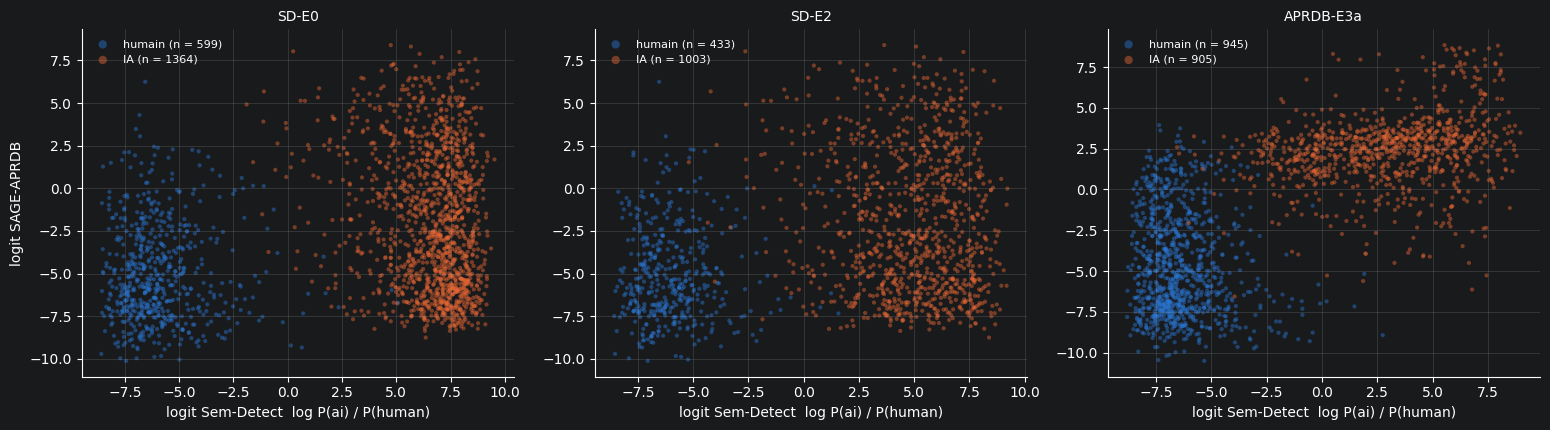

In [12]:
# notebook : hybrid_svm.ipynb — cellule 12 : espace de décision (logit Sem-Detect contre logit SAGE-APRDB)
COLORS = {0: ("#2a78d6", "humain"), 1: ("#eb6834", "IA")}
fig, axes = plt.subplots(1, len(DATA), figsize=(5.2 * len(DATA), 4.4))
for ax, (ds, T) in zip(axes, DATA.items()):
    for c in (0, 1):
        sub = T[T["y"] == c]
        ax.scatter(sub["sd_ai"], sub["z_SAGE-APRDB"], s=9, alpha=0.45, color=COLORS[c][0],
                   edgecolor="none", label=f"{COLORS[c][1]} (n = {len(sub)})")
    ax.set_title(ds, fontsize=10)
    ax.set_xlabel("logit Sem-Detect  log P(ai) / P(human)")
    ax.grid(alpha=0.25, lw=0.5)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(loc="upper left", frameon=False, fontsize=8, markerscale=2)
axes[0].set_ylabel("logit SAGE-APRDB")
fig.tight_layout()
fig.savefig(HYB_DIR / "espace_decision.png", dpi=150)
plt.show()

In [13]:
# notebook : hybrid_svm.ipynb — cellule 13 : export
out_dir = HYB_DIR / "tables"
out_dir.mkdir(exist_ok=True)
for key, tab in TABLES.items():
    tab.to_csv(out_dir / f"{key}.csv")
for ds, T in DATA.items():
    oof = T.drop(columns=["group"]).copy()
    for name, s in SCORES[ds].items():
        oof[f"score::{name}"] = s
    oof.to_parquet(HYB_DIR / f"scores_hors_pli_{ds}.parquet")
print(f"{len(TABLES)} tableaux -> {out_dir} | scores hors pli -> {HYB_DIR}")

17 tableaux -> /data2/cyaiche/cache_dir/hybrid_svm/tables | scores hors pli -> /data2/cyaiche/cache_dir/hybrid_svm


## Lecture

1. **Les contrôles** (cellules 4 à 6) : Sem-Detect doit reproduire E0, E2 et E3 (a), et la saturation de SAGE doit rester marginale. Si elle dépasse environ 1 %, il faut exposer le logit brut dans `sage.py` avant de conclure : les ex æquo aux extrêmes biaisent le SVM.
2. **La complémentarité** (cellule 7) : une corrélation forte entre `sd_ai` et `z_SAGE-*` à classe fixée annonce un gain faible, quel que soit le classifieur.
3. **La réponse principale** (cellule 9) : la ligne « Hybride − Sem-Detect (SVM) ». Un IC95 qui exclut 0 indique un apport de SAGE dans ce dataset. En E0, Sem-Detect est au plafond (AUC ≈ 0,998) : seul le TPR@1 % peut bouger. E2 et APRDB sont les cas informatifs.
4. **Le transfert** (cellule 10) : c'est la question pratique. Une fusion qui aide en validation croisée, mais pas d'un dataset à l'autre, a appris des poids propres au domaine.
5. **Les poids linéaires** (cellule 11) : la part du poids donnée à SAGE, dataset par dataset. Elle devrait être faible sur Sem-Detect DB pour SAGE-APRDB et forte sur APRDB, ce qui explique les échecs de transfert éventuels.

In [14]:
# notebook : hybrid_svm.ipynb — cellule 14 : impression texte copiable + fichier resultats.txt
import os
from pathlib import Path

import pandas as pd

HYB_DIR = Path(os.environ["CACHE_DIR"]) / "hybrid_svm"

try:
    tables = dict(TABLES)                     # kernel encore vivant
except NameError:                             # kernel redémarré : relecture des CSV exportés (cellule 13)
    tables = {p.stem: pd.read_csv(p, index_col=0) for p in sorted((HYB_DIR / "tables").glob("*.csv"))}

blocks = []
with pd.option_context("display.width", 250, "display.max_columns", None,
                       "display.max_rows", None, "display.max_colwidth", None,
                       "display.float_format", "{:.4f}".format):
    for key, tab in tables.items():
        blocks.append(f"===== {key} =====\n{tab.to_string()}\n")
text = "\n".join(blocks)

out = HYB_DIR / "resultats.txt"
out.write_text(text, encoding="utf-8")
print(text)
print(f"\n-> {out}")

===== saturation_SAGE =====
                          saturés à 1  saturés à 0  logit min  logit max
SAGE-APRDB Sem-Detect DB       0.0000       0.0000   -10.1138     8.3918
           APRDB pilote        0.0000       0.0000   -10.5037     8.8422
SAGE-SD    Sem-Detect DB       0.0000       0.0000   -10.9619    10.1046
           APRDB pilote        0.0000       0.0000   -11.0477     8.4936

===== correlations_par_classe =====
                                sd_ai   sd_rw  z_SAGE-APRDB  z_SAGE-SD
SD-E0     IA     sd_ai         1.0000  0.0070       -0.1540    -0.0290
                 sd_rw         0.0070  1.0000       -0.1450    -0.0390
                 z_SAGE-APRDB -0.1540 -0.1450        1.0000    -0.0030
                 z_SAGE-SD    -0.0290 -0.0390       -0.0030     1.0000
          humain sd_ai         1.0000  0.8800        0.0090     0.0710
                 sd_rw         0.8800  1.0000        0.0280     0.0530
                 z_SAGE-APRDB  0.0090  0.0280        1.0000     0.3400
  

In [15]:
# notebook : hybrid_svm.ipynb — cellule 15 : tableau du papier (ensembles communs) + hybride + accuracy maximale
# 1) ensembles communs du papier : Sem-Detect = E0 ∩ E1 ∩ E2 ; APRDB = (a) ∩ (b)
P_E1 = run_semdetect(store_loc, paper_protocol_references(te, k=3, seed=0, is_valid=valid_in(store_loc)),
                     te["review-id"])
df_b = universe.copy()
df_b["review-id"] = "aprdb:b:" + df_b["uid"]
df_b["content"] = df_b["content"].map(CLEANERS["b"])
store_b = SemDetectFeatureStore(root=STORE_ROOT, claims_source=CLAIMS_TAG, text_source="aprdb:test:clean_b",
                                device=FEATURES_DEVICE)
refs_b = paper_protocol_references(df_b, k=3, seed=0, key_cols=["group"],
                                   is_valid=lambda rid: store_b.semantic(rid, 1) is not None)
P_Bb = run_semdetect(store_b, refs_b, df_b.loc[df_b["is_target"], "review-id"])
P_Bb.index = [r[len("aprdb:b:"):] for r in P_Bb.index]

common_sd = P_SD["E0"].index.intersection(P_E1.index).intersection(P_SD["E2"].index)
common_ap = P_B.index.intersection(P_Bb.index)
T_SD = build_table(P_SD["E0"].loc[common_sd], te_idx, Z_SD, "submission_id")   # Sem-Detect en E0
T_AP = build_table(P_B.loc[common_ap], meta_B, Z_B, "group")                   # Sem-Detect en (a)
TESTS = {"APRDB": T_AP, "Sem-Detect": T_SD}
for name, T, n0, a0, g0 in (("Sem-Detect", T_SD, 1432, 1000, 138), ("APRDB", T_AP, 1841, 903, 990)):
    ok = len(T) == n0 and T["y"].sum() == a0 and T["group"].nunique() == g0
    print(f"{'✅' if ok else '⚠️'} {name} : N={len(T)} (IA {T['y'].sum()}, humaines {(1 - T['y']).sum()}), "
          f"groupes {T['group'].nunique()} | attendu N={n0}, IA {a0}, groupes {g0}")


# 2) métriques, dont l'accuracy maximale (seuil oracle choisi sur le test)
def max_accuracy(y: np.ndarray, s: np.ndarray) -> float:
    fpr, tpr, _ = roc_curve(y, s, drop_intermediate=False)
    pos, neg = y.sum(), len(y) - y.sum()
    return float(((tpr * pos + (1 - fpr) * neg) / len(y)).max())


def metrics_row(T: pd.DataFrame, s: pd.Series) -> dict:
    y, v = T["y"].to_numpy(), s.reindex(T.index).to_numpy(dtype=float)
    if np.isnan(v).any():
        raise ValueError(f"{int(np.isnan(v).sum())} score(s) manquant(s)")
    return {**all_metrics(y, v), "Acc max": max_accuracy(y, v)}


# probabilités SAGE brutes (cache, instantané) : identiques aux valeurs déjà dans le tableau
RAW = {name: {"Sem-Detect": sage_scores(name, "sd:" + te["review-id"], te["content"]).set_axis(te["review-id"].to_numpy()),
              "APRDB": sage_scores(name, "aprdb:" + meta_B.index.to_series(), meta_B["content"]).set_axis(meta_B.index.to_numpy())}
       for name in SAGE_PRESETS}

rows = {}
for det in SAGE_PRESETS:
    rows[det] = {(ds, k): v for ds, T in TESTS.items() for k, v in metrics_row(T, RAW[det][ds]).items()}
rows["Sem-Detect"] = {(ds, k): v for ds, T in TESTS.items() for k, v in metrics_row(T, T["sd_p_ai"]).items()}

# 3) SVM linéaire : validation croisée imbriquée groupée sur son dataset, transfert sans réajustement sur l'autre
SVM_SETS = {"Sem-Detect (SVM)": ["sd_ai", "sd_rw"], "Hybrid (SVM)": ["sd_ai", "sd_rw", "z_SAGE-APRDB"]}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for fs, cols in SVM_SETS.items():
        for train_name, T_train in TESTS.items():
            label = f"{fs}, fit on {train_name}"
            rows[label] = {}
            for ds, T in TESTS.items():
                if ds == train_name:
                    s = oof_scores(T, cols, "lin")[0]
                else:
                    m = make_model("lin").fit(T_train[cols].to_numpy(), T_train["y"].to_numpy(),
                                              groups=T_train["group"].to_numpy())
                    s = pd.Series(m.decision_function(T[cols].to_numpy()), index=T.index)
                rows[label].update({(ds, k): v for k, v in metrics_row(T, s).items()})

paper = pd.DataFrame.from_dict(rows, orient="index")
paper.columns = pd.MultiIndex.from_tuples(paper.columns)
TABLES["paper_cross_dataset"] = paper
display(paper.round(4))

# 4) contrôle contre les AUC déjà publiées dans le tableau
EXPECT = {("SAGE-APRDB", "APRDB"): 0.9590, ("SAGE-APRDB", "Sem-Detect"): 0.7208,
          ("SAGE-SD", "APRDB"): 0.7971, ("SAGE-SD", "Sem-Detect"): 0.9999,
          ("Sem-Detect", "APRDB"): 0.9801, ("Sem-Detect", "Sem-Detect"): 0.9987}
for (det, ds), v0 in EXPECT.items():
    v = paper.loc[det, (ds, "AUC")]
    print(f"{'✅' if abs(v - v0) < 5e-4 else '⚠️'} {det} sur {ds} : AUC {v:.4f} (tableau {v0})")
for ds, T in TESTS.items():
    print(f"accuracy de la classe majoritaire, {ds} : {max(T['y'].mean(), 1 - T['y'].mean()):.4f}")

# 5) lignes LaTeX
METRICS_TEX = ["AUC", "TPR@1%", "TPR@5%", "Acc max"]
print("\n".join(f"    {det} & " + " & ".join(f"{r[(ds, m)]:.4f}" for ds in ("APRDB", "Sem-Detect") for m in METRICS_TEX)
                + r" \\" for det, r in paper.iterrows()))

INFO:src.detector.sem_detect.feature_store:Feature store : 15422 embeddings (fbbbe1608d0e), 1918 stats textuelles (cf890d2baa4a)


✅ Sem-Detect : N=1432 (IA 1000, humaines 432), groupes 138 | attendu N=1432, IA 1000, groupes 138
✅ APRDB : N=1841 (IA 903, humaines 938), groupes 990 | attendu N=1841, IA 903, groupes 990
SAGE-APRDB : 4410 en cache, 0 à scorer
SAGE-APRDB : 1918 en cache, 0 à scorer
SAGE-SD : 4410 en cache, 0 à scorer
SAGE-SD : 1918 en cache, 0 à scorer


APRDB                          \
                                        AUC  TPR@1%  TPR@5% Acc max   
SAGE-APRDB                           0.9590  0.5161  0.7530  0.8919   
SAGE-SD                              0.7971  0.0509  0.1661  0.7496   
Sem-Detect                           0.9801  0.6999  0.9059  0.9424   
Sem-Detect (SVM), fit on APRDB       0.9928  0.8738  0.9779  0.9647   
Sem-Detect (SVM), fit on Sem-Detect  0.9932  0.8649  0.9790  0.9658   
Hybrid (SVM), fit on APRDB           0.9984  0.9845  0.9956  0.9875   
Hybrid (SVM), fit on Sem-Detect      0.9982  0.9756  0.9911  0.9842   

                                    Sem-Detect                        
                                           AUC TPR@1% TPR@5% Acc max  
SAGE-APRDB                              0.7208  0.206  0.351  0.7277  
SAGE-SD                                 0.9999  0.997  0.998  0.9965  
Sem-Detect                              0.9987  0.967  0.999  0.9867  
Sem-Detect (SVM), fit on APRDB          0.9997  0.995  1.000  0.9937  
Sem-Detect (SVM), fit on Sem-Detect     0.9992  0.995  1.000  0.9937  
Hybrid (SVM), fit on APRDB              0.9996  0.985  1.000  0.9902  
Hybrid (SVM), fit on Sem-Detect         0.9998  0.996  1.000  0.9951

✅ SAGE-APRDB sur APRDB : AUC 0.9590 (tableau 0.959)
✅ SAGE-APRDB sur Sem-Detect : AUC 0.7208 (tableau 0.7208)
✅ SAGE-SD sur APRDB : AUC 0.7971 (tableau 0.7971)
✅ SAGE-SD sur Sem-Detect : AUC 0.9999 (tableau 0.9999)
✅ Sem-Detect sur APRDB : AUC 0.9801 (tableau 0.9801)
✅ Sem-Detect sur Sem-Detect : AUC 0.9987 (tableau 0.9987)
accuracy de la classe majoritaire, APRDB : 0.5095
accuracy de la classe majoritaire, Sem-Detect : 0.6983
    SAGE-APRDB & 0.9590 & 0.5161 & 0.7530 & 0.8919 & 0.7208 & 0.2060 & 0.3510 & 0.7277 \\
    SAGE-SD & 0.7971 & 0.0509 & 0.1661 & 0.7496 & 0.9999 & 0.9970 & 0.9980 & 0.9965 \\
    Sem-Detect & 0.9801 & 0.6999 & 0.9059 & 0.9424 & 0.9987 & 0.9670 & 0.9990 & 0.9867 \\
    Sem-Detect (SVM), fit on APRDB & 0.9928 & 0.8738 & 0.9779 & 0.9647 & 0.9997 & 0.9950 & 1.0000 & 0.9937 \\
    Sem-Detect (SVM), fit on Sem-Detect & 0.9932 & 0.8649 & 0.9790 & 0.9658 & 0.9992 & 0.9950 & 1.0000 & 0.9937 \\
    Hybrid (SVM), fit on APRDB & 0.9984 & 0.9845 & 0.9956 & 0.9875 & 0.9996 &

✅ SAGE-APRDB                       APRDB       AUROC 0.9590 (tableau 0.9590)
✅ SAGE-APRDB                       Sem-Detect  AUROC 0.7208 (tableau 0.7208)
✅ SAGE-SD                          APRDB       AUROC 0.7971 (tableau 0.7971)
✅ SAGE-SD                          Sem-Detect  AUROC 0.9999 (tableau 0.9999)
✅ Sem-Detect                       APRDB       AUROC 0.9801 (tableau 0.9801)
✅ Sem-Detect                       Sem-Detect  AUROC 0.9987 (tableau 0.9987)
✅ Hybrid (SVM), fit on APRDB       APRDB       AUROC 0.9984 (tableau 0.9984)
✅ Hybrid (SVM), fit on APRDB       Sem-Detect  AUROC 0.9996 (tableau 0.9996)
✅ Hybrid (SVM), fit on Sem-Detect  APRDB       AUROC 0.9982 (tableau 0.9982)
✅ Hybrid (SVM), fit on Sem-Detect  Sem-Detect  AUROC 0.9998 (tableau 0.9998)


INFO:fontTools.subset:maxp pruned
INFO:fontTools.subset:cmap pruned
INFO:fontTools.subset:kern dropped
INFO:fontTools.subset:post pruned
INFO:fontTools.subset:FFTM dropped
INFO:fontTools.subset:GPOS pruned
INFO:fontTools.subset:GSUB pruned
INFO:fontTools.subset:glyf pruned
INFO:fontTools.subset:Added gid0 to subset
INFO:fontTools.subset:Added first four glyphs to subset
INFO:fontTools.subset:Closing glyph list over 'MATH': 55 glyphs before
INFO:fontTools.subset:Glyph names: ['.notdef', '.null', 'A', 'B', 'D', 'E', 'F', 'G', 'H', 'M', 'N', 'P', 'R', 'S', 'T', 'V', 'a', 'b', 'c', 'colon', 'comma', 'd', 'e', 'eight', 'equal', 'f', 'five', 'four', 'g', 'h', 'hyphen', 'i', 'l', 'm', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'percent', 'period', 'r', 's', 'six', 'space', 't', 'three', 'two', 'u', 'v', 'y', 'zero']
INFO:fontTools.subset:Glyph IDs:   [0, 1, 2, 3, 8, 11, 12, 15, 16, 17, 19, 20, 21, 22, 23, 24, 25, 27, 28, 29, 32, 36, 37, 39, 40, 41, 42, 43, 48

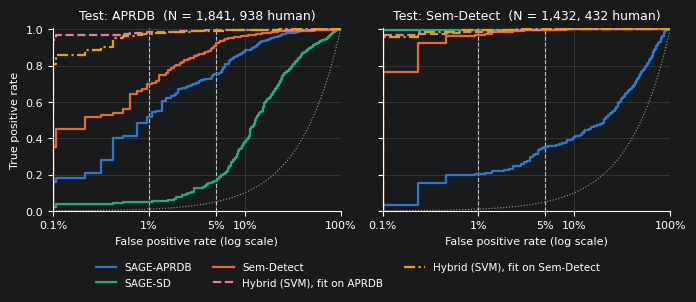

-> /data2/cyaiche/cache_dir/hybrid_svm/roc_cross_dataset.pdf


In [16]:
# notebook : hybrid_svm.ipynb — cellule 16 : courbes ROC des lignes du tableau cross-dataset (figure du papier)
# Prérequis : cellule 15 exécutée (TESTS, RAW, SVM_SETS, paper).

# 1) scores de chaque ligne du tableau, sur les mêmes ensembles (APRDB N=1841, Sem-Detect N=1432)
CURVES = {det: {ds: RAW[det][ds] for ds in TESTS} for det in SAGE_PRESETS}
CURVES["Sem-Detect"] = {ds: T["sd_p_ai"] for ds, T in TESTS.items()}
HYB_COLS = SVM_SETS["Hybrid (SVM)"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for train_name, T_train in TESTS.items():
        label = f"Hybrid (SVM), fit on {train_name}"
        fitted = make_model("lin").fit(T_train[HYB_COLS].to_numpy(), T_train["y"].to_numpy(),
                                       groups=T_train["group"].to_numpy())
        CURVES[label] = {}
        for ds, T in TESTS.items():
            if ds == train_name:   # dataset d'ajustement : scores hors pli (mêmes graines que la cellule 15)
                CURVES[label][ds] = oof_scores(T, HYB_COLS, "lin")[0]
            else:                  # transfert : appliqué sans réajustement
                CURVES[label][ds] = pd.Series(fitted.decision_function(T[HYB_COLS].to_numpy()), index=T.index)

# contrôle : chaque courbe doit redonner l'AUROC du tableau
for det, by_ds in CURVES.items():
    for ds, s in by_ds.items():
        v = roc_auc_score(TESTS[ds]["y"].to_numpy(), s.reindex(TESTS[ds].index).to_numpy(dtype=float))
        ref = paper.loc[det, (ds, "AUC")]
        print(f"{'✅' if abs(v - ref) < 1e-6 else '⚠️'} {det:<32} {ds:<11} AUROC {v:.4f} (tableau {ref:.4f})")

# 2) figure : un panneau par jeu de test, mêmes couleurs et styles par détecteur
ROC_STYLE = {   # palette catégorielle en ordre fixe ; le style de trait double la couleur (impression N&B, daltonisme)
    "SAGE-APRDB": ("#2a78d6", "-"),
    "SAGE-SD": ("#1baf7a", "-"),
    "Sem-Detect": ("#eb6834", "-"),
    "Hybrid (SVM), fit on APRDB": ("#e87ba4", "--"),
    "Hybrid (SVM), fit on Sem-Detect": ("#eda100", (0, (5, 1.5, 1, 1.5))),
}
LOG_X, X_MIN = True, 1e-3   # échelle log : rend lisible la zone des faibles FPR (1 %, 5 %)

with plt.rc_context({"font.size": 8, "axes.titlesize": 9, "legend.fontsize": 7.5,
                     "pdf.fonttype": 42, "ps.fonttype": 42}):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.0), sharey=True)
    for ax, ds in zip(axes, ("APRDB", "Sem-Detect")):
        y = TESTS[ds]["y"].to_numpy()
        for det, (color, ls) in ROC_STYLE.items():
            s = CURVES[det][ds].reindex(TESTS[ds].index).to_numpy(dtype=float)
            fpr, tpr, _ = roc_curve(y, s)
            ax.plot(np.clip(fpr, X_MIN, 1.0) if LOG_X else fpr, tpr, color=color, ls=ls, lw=1.6, label=det)
        grid_x = np.logspace(np.log10(X_MIN), 0, 200) if LOG_X else np.linspace(0, 1, 2)
        ax.plot(grid_x, grid_x, color="#9a9a9a", lw=0.8, ls=":", zorder=0)   # hasard
        for x in (0.01, 0.05):
            ax.axvline(x, color="#c8c8c8", lw=0.8, ls="--", zorder=0)
        if LOG_X:
            ax.set_xscale("log")
            ax.set_xlim(X_MIN, 1.0)
            ax.set_xticks([1e-3, 1e-2, 5e-2, 1e-1, 1.0], ["0.1%", "1%", "5%", "10%", "100%"])
            ax.minorticks_off()
        else:
            ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.01)
        n_neg = int((1 - y).sum())
        ax.set_title(f"Test: {ds}  (N = {len(y):,}, {n_neg} human)")
        ax.set_xlabel("False positive rate" + (" (log scale)" if LOG_X else ""))
        ax.grid(alpha=0.25, lw=0.5)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[0].set_ylabel("True positive rate")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0))
    fig.tight_layout(rect=(0, 0.13, 1, 1))
    for ext in ("pdf", "png"):
        fig.savefig(HYB_DIR / f"roc_cross_dataset.{ext}", dpi=300, bbox_inches="tight")
    plt.show()
print(f"-> {HYB_DIR / 'roc_cross_dataset.pdf'}")

✅ SAGE-APRDB                       APRDB       AUROC 0.9590 (tableau 0.9590)
✅ SAGE-APRDB                       Sem-Detect  AUROC 0.7208 (tableau 0.7208)
✅ SAGE-SD                          APRDB       AUROC 0.7971 (tableau 0.7971)
✅ SAGE-SD                          Sem-Detect  AUROC 0.9999 (tableau 0.9999)
✅ Sem-Detect                       APRDB       AUROC 0.9801 (tableau 0.9801)
✅ Sem-Detect                       Sem-Detect  AUROC 0.9987 (tableau 0.9987)
✅ Hybrid (SVM), fit on APRDB       APRDB       AUROC 0.9984 (tableau 0.9984)
✅ Hybrid (SVM), fit on APRDB       Sem-Detect  AUROC 0.9996 (tableau 0.9996)
✅ Hybrid (SVM), fit on Sem-Detect  APRDB       AUROC 0.9982 (tableau 0.9982)
✅ Hybrid (SVM), fit on Sem-Detect  Sem-Detect  AUROC 0.9998 (tableau 0.9998)


INFO:fontTools.subset:maxp pruned
INFO:fontTools.subset:cmap pruned
INFO:fontTools.subset:kern dropped
INFO:fontTools.subset:post pruned
INFO:fontTools.subset:FFTM dropped
INFO:fontTools.subset:GPOS pruned
INFO:fontTools.subset:GSUB pruned
INFO:fontTools.subset:glyf pruned
INFO:fontTools.subset:Added gid0 to subset
INFO:fontTools.subset:Added first four glyphs to subset
INFO:fontTools.subset:Closing glyph list over 'MATH': 54 glyphs before
INFO:fontTools.subset:Glyph names: ['.notdef', '.null', 'A', 'B', 'D', 'E', 'F', 'G', 'H', 'M', 'N', 'P', 'R', 'S', 'T', 'V', 'a', 'b', 'c', 'colon', 'comma', 'd', 'e', 'eight', 'equal', 'f', 'five', 'four', 'h', 'hyphen', 'i', 'l', 'm', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'percent', 'period', 'r', 's', 'six', 'space', 't', 'three', 'two', 'u', 'v', 'y', 'zero']
INFO:fontTools.subset:Glyph IDs:   [0, 1, 2, 3, 8, 11, 12, 15, 16, 17, 19, 20, 21, 22, 23, 24, 25, 27, 28, 29, 32, 36, 37, 39, 40, 41, 42, 43, 48, 49,

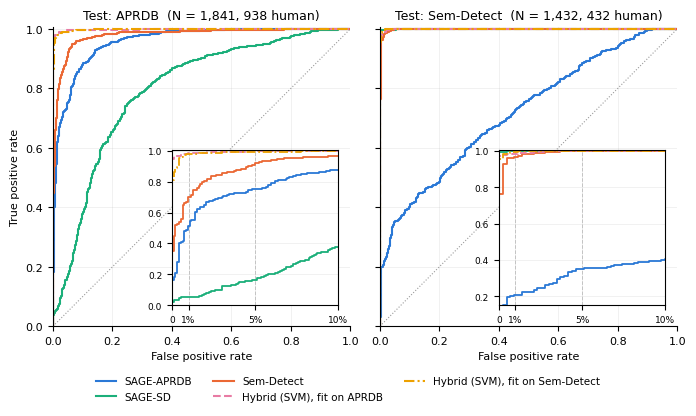

-> /data2/cyaiche/cache_dir/hybrid_svm/roc_cross_dataset.pdf


In [19]:
# notebook : hybrid_svm.ipynb — cellule 16 : courbes ROC des lignes du tableau cross-dataset (figure du papier)
# Prérequis : cellule 15 exécutée (TESTS, RAW, SVM_SETS, paper).

# 1) scores de chaque ligne du tableau, sur les mêmes ensembles (APRDB N=1841, Sem-Detect N=1432)
CURVES = {det: {ds: RAW[det][ds] for ds in TESTS} for det in SAGE_PRESETS}
CURVES["Sem-Detect"] = {ds: T["sd_p_ai"] for ds, T in TESTS.items()}
HYB_COLS = SVM_SETS["Hybrid (SVM)"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for train_name, T_train in TESTS.items():
        label = f"Hybrid (SVM), fit on {train_name}"
        fitted = make_model("lin").fit(T_train[HYB_COLS].to_numpy(), T_train["y"].to_numpy(),
                                       groups=T_train["group"].to_numpy())
        CURVES[label] = {}
        for ds, T in TESTS.items():
            if ds == train_name:   # dataset d'ajustement : scores hors pli (mêmes graines que la cellule 15)
                CURVES[label][ds] = oof_scores(T, HYB_COLS, "lin")[0]
            else:                  # transfert : appliqué sans réajustement
                CURVES[label][ds] = pd.Series(fitted.decision_function(T[HYB_COLS].to_numpy()), index=T.index)

# contrôle : chaque courbe doit redonner l'AUROC du tableau
for det, by_ds in CURVES.items():
    for ds, s in by_ds.items():
        v = roc_auc_score(TESTS[ds]["y"].to_numpy(), s.reindex(TESTS[ds].index).to_numpy(dtype=float))
        ref = paper.loc[det, (ds, "AUC")]
        print(f"{'✅' if abs(v - ref) < 1e-6 else '⚠️'} {det:<32} {ds:<11} AUROC {v:.4f} (tableau {ref:.4f})")

# 2) figure : ROC standard (axes linéaires 0–1, diagonale du hasard), un panneau par jeu de test,
#    avec un encart qui agrandit la zone des faibles FPR (0–10 %), là où les détecteurs se séparent
ROC_STYLE = {   # palette catégorielle en ordre fixe ; le style de trait double la couleur (impression N&B, daltonisme)
    "SAGE-APRDB": ("#2a78d6", "-"),
    "SAGE-SD": ("#1baf7a", "-"),
    "Sem-Detect": ("#eb6834", "-"),
    "Hybrid (SVM), fit on APRDB": ("#e87ba4", "--"),
    "Hybrid (SVM), fit on Sem-Detect": ("#eda100", (0, (5, 1.5, 1, 1.5))),
}
ZOOM_FPR = 0.10   # borne droite de l'encart
# notebook : hybrid_svm.ipynb — cellule 16 : remplace la ligne `with plt.rc_context({...}):`
with plt.style.context("default"), plt.rc_context({"font.size": 8, "axes.titlesize": 9, "legend.fontsize": 7.5,
                                                   "pdf.fonttype": 42, "ps.fonttype": 42}):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 4.1), sharey=True)
    for ax, ds in zip(axes, ("APRDB", "Sem-Detect")):
        y = TESTS[ds]["y"].to_numpy()
        axins = ax.inset_axes([0.40, 0.07, 0.56, 0.52])
        tpr_at_1 = []
        for det, (color, ls) in ROC_STYLE.items():
            s = CURVES[det][ds].reindex(TESTS[ds].index).to_numpy(dtype=float)
            fpr, tpr, _ = roc_curve(y, s)   # commence en (0, 0), finit en (1, 1)
            ax.plot(fpr, tpr, color=color, ls=ls, lw=1.5, label=det)
            axins.plot(fpr, tpr, color=color, ls=ls, lw=1.3)
            tpr_at_1.append(np.interp(0.01, fpr, tpr))
        ax.plot([0, 1], [0, 1], color="#9a9a9a", lw=0.8, ls=":", zorder=0)   # hasard
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.005)
        ax.set_aspect("equal")
        n_neg = int((1 - y).sum())
        ax.set_title(f"Test: {ds}  (N = {len(y):,}, {n_neg} human)")
        ax.set_xlabel("False positive rate")
        ax.grid(alpha=0.25, lw=0.5)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)

        # encart : FPR de 0 à ZOOM_FPR, repères à 1 % et 5 %
        y_low = max(0.0, np.floor(min(tpr_at_1) * 10) / 10 - 0.05)   # toutes les courbes visibles dès 1 %
        axins.set_xlim(0, ZOOM_FPR)
        axins.set_ylim(y_low, 1.005)
        for x in (0.01, 0.05):
            axins.axvline(x, color="#c8c8c8", lw=0.7, ls="--", zorder=0)
        axins.set_xticks([0, 0.01, 0.05, ZOOM_FPR], ["0", "1%", "5%", f"{ZOOM_FPR:.0%}"])
        axins.tick_params(labelsize=6.5)
        axins.grid(alpha=0.25, lw=0.5)
    axes[0].set_ylabel("True positive rate")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0))
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    for ext in ("pdf", "png"):
        fig.savefig(HYB_DIR / f"roc_cross_dataset.{ext}", dpi=300, bbox_inches="tight")
    plt.show()
print(f"-> {HYB_DIR / 'roc_cross_dataset.pdf'}")

✅ SAGE-APRDB                       APRDB       AUROC 0.9590 (tableau 0.9590)
✅ SAGE-APRDB                       Sem-Detect  AUROC 0.7208 (tableau 0.7208)
✅ SAGE-SD                          APRDB       AUROC 0.7971 (tableau 0.7971)
✅ SAGE-SD                          Sem-Detect  AUROC 0.9999 (tableau 0.9999)
✅ Sem-Detect                       APRDB       AUROC 0.9801 (tableau 0.9801)
✅ Sem-Detect                       Sem-Detect  AUROC 0.9987 (tableau 0.9987)
✅ Hybrid (SVM), fit on APRDB       APRDB       AUROC 0.9984 (tableau 0.9984)
✅ Hybrid (SVM), fit on APRDB       Sem-Detect  AUROC 0.9996 (tableau 0.9996)
✅ Hybrid (SVM), fit on Sem-Detect  APRDB       AUROC 0.9982 (tableau 0.9982)
✅ Hybrid (SVM), fit on Sem-Detect  Sem-Detect  AUROC 0.9998 (tableau 0.9998)


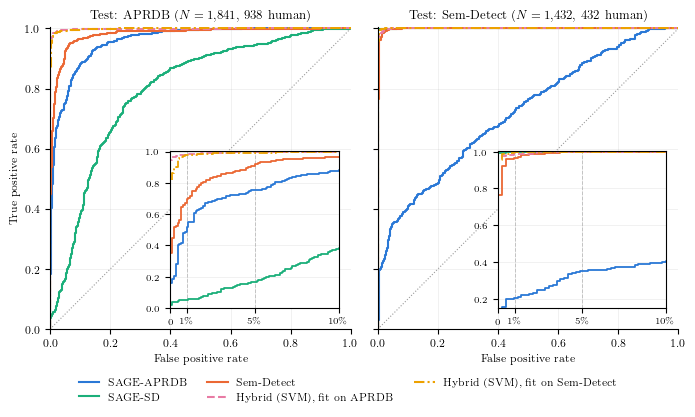

-> /data2/cyaiche/cache_dir/hybrid_svm/roc_cross_dataset.pdf


In [20]:
# notebook : hybrid_svm.ipynb — cellule 16 : courbes ROC des lignes du tableau cross-dataset (figure du papier)
# Prérequis : cellule 15 exécutée (TESTS, RAW, SVM_SETS, paper).
# Rendu LaTeX (text.usetex) : nécessite une distribution TeX, dvipng (PNG) et Ghostscript (PDF).

# 1) scores de chaque ligne du tableau, sur les mêmes ensembles (APRDB N=1841, Sem-Detect N=1432)
CURVES = {det: {ds: RAW[det][ds] for ds in TESTS} for det in SAGE_PRESETS}
CURVES["Sem-Detect"] = {ds: T["sd_p_ai"] for ds, T in TESTS.items()}
HYB_COLS = SVM_SETS["Hybrid (SVM)"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for train_name, T_train in TESTS.items():
        label = f"Hybrid (SVM), fit on {train_name}"
        fitted = make_model("lin").fit(T_train[HYB_COLS].to_numpy(), T_train["y"].to_numpy(),
                                       groups=T_train["group"].to_numpy())
        CURVES[label] = {}
        for ds, T in TESTS.items():
            if ds == train_name:   # dataset d'ajustement : scores hors pli (mêmes graines que la cellule 15)
                CURVES[label][ds] = oof_scores(T, HYB_COLS, "lin")[0]
            else:                  # transfert : appliqué sans réajustement
                CURVES[label][ds] = pd.Series(fitted.decision_function(T[HYB_COLS].to_numpy()), index=T.index)

# contrôle : chaque courbe doit redonner l'AUROC du tableau
for det, by_ds in CURVES.items():
    for ds, s in by_ds.items():
        v = roc_auc_score(TESTS[ds]["y"].to_numpy(), s.reindex(TESTS[ds].index).to_numpy(dtype=float))
        ref = paper.loc[det, (ds, "AUC")]
        print(f"{'✅' if abs(v - ref) < 1e-6 else '⚠️'} {det:<32} {ds:<11} AUROC {v:.4f} (tableau {ref:.4f})")

# 2) figure : ROC standard (axes linéaires 0–1, diagonale du hasard), un panneau par jeu de test,
#    avec un encart qui agrandit la zone des faibles FPR (0–10 %), là où les détecteurs se séparent
ROC_STYLE = {   # palette catégorielle en ordre fixe ; le style de trait double la couleur (impression N&B, daltonisme)
    "SAGE-APRDB": ("#2a78d6", "-"),
    "SAGE-SD": ("#1baf7a", "-"),
    "Sem-Detect": ("#eb6834", "-"),
    "Hybrid (SVM), fit on APRDB": ("#e87ba4", "--"),
    "Hybrid (SVM), fit on Sem-Detect": ("#eda100", (0, (5, 1.5, 1, 1.5))),
}
ZOOM_FPR = 0.10   # borne droite de l'encart

_TEX_SPECIALS = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#",
                 "_": r"\_", "{": r"\{", "}": r"\}", "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}

def tex_escape(text: str) -> str:
    """Échappe les caractères réservés de TeX (sinon la compilation de l'étiquette échoue sous usetex)."""
    return "".join(_TEX_SPECIALS.get(c, c) for c in text)

def tex_int(n: int) -> str:
    """Entier avec séparateur de milliers, en mode math : '{,}' évite l'espace de ponctuation après la virgule."""
    return f"{n:,}".replace(",", "{,}")

TEX_RC = {
    "text.usetex": True,                                  # tout le texte passe par LaTeX
    "font.family": "serif",                               # Computer Modern, cohérent avec le corps du papier
    "text.latex.preamble": r"\usepackage{amsmath}",
    "font.size": 8,
    "axes.titlesize": 9,
    "legend.fontsize": 7.5,
}

with plt.style.context("default"), plt.rc_context(TEX_RC):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 4.1), sharey=True)
    for ax, ds in zip(axes, ("APRDB", "Sem-Detect")):
        y = TESTS[ds]["y"].to_numpy()
        axins = ax.inset_axes([0.40, 0.07, 0.56, 0.52])
        tpr_at_1 = []
        for det, (color, ls) in ROC_STYLE.items():
            s = CURVES[det][ds].reindex(TESTS[ds].index).to_numpy(dtype=float)
            fpr, tpr, _ = roc_curve(y, s)   # commence en (0, 0), finit en (1, 1)
            ax.plot(fpr, tpr, color=color, ls=ls, lw=1.5, label=tex_escape(det))
            axins.plot(fpr, tpr, color=color, ls=ls, lw=1.3)
            tpr_at_1.append(np.interp(0.01, fpr, tpr))
        ax.plot([0, 1], [0, 1], color="#9a9a9a", lw=0.8, ls=":", zorder=0)   # hasard
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.005)
        ax.set_aspect("equal")
        n_neg = int((1 - y).sum())
        ax.set_title(rf"Test: {tex_escape(ds)} ($N = {tex_int(len(y))}$, ${tex_int(n_neg)}$ human)")
        ax.set_xlabel(r"False positive rate")
        ax.grid(alpha=0.25, lw=0.5)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)

        # encart : FPR de 0 à ZOOM_FPR, repères à 1 % et 5 %
        y_low = max(0.0, np.floor(min(tpr_at_1) * 10) / 10 - 0.05)   # toutes les courbes visibles dès 1 %
        axins.set_xlim(0, ZOOM_FPR)
        axins.set_ylim(y_low, 1.005)
        for x in (0.01, 0.05):
            axins.axvline(x, color="#c8c8c8", lw=0.7, ls="--", zorder=0)
        axins.set_xticks([0, 0.01, 0.05, ZOOM_FPR],
                         [r"$0$", r"$1\%$", r"$5\%$", rf"${ZOOM_FPR * 100:.0f}\%$"])
        axins.tick_params(labelsize=6.5)
        axins.grid(alpha=0.25, lw=0.5)
    axes[0].set_ylabel(r"True positive rate")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0))
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    for ext in ("pdf", "png"):
        fig.savefig(HYB_DIR / f"roc_cross_dataset.{ext}", dpi=300, bbox_inches="tight")
    plt.show()
print(f"-> {HYB_DIR / 'roc_cross_dataset.pdf'}")